<a href="https://colab.research.google.com/github/deira-v/MachineLearningwPython/blob/main/CampusDataProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Campus Dataset Project**
Deira valci, 2026

## **Data Preparation**
This selection loads the campus dataset and prepares it for analysis

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### **Load the Dataframe**
Read the encoded data

In [3]:
df = pd.read_csv('/content/drive/MyDrive/MachineLearningwPython/CampusWalkDataset_Deira.csv', skiprows=4)

print(df.dtypes)
print(f"\n Dataset loaded successfully! Total rows: {df.shape[0]}, Columns: {df.shape[1]}")


recorder_id                               object
date                                      object
location                                  object
weather                                   object
temperature_c                             object
sound level                               object
foot_traffic                              object
primary_sound_type_urban                  object
other_sound_type_urban                    object
primary_sound_type_nature                 object
other_sound_type_nature                   object
insects_count                            float64
birds_count                              float64
trees_presence                            object
native_or_wild_plant_presence             object
ornnamental_or_planted_plant_presence     object
moss_or_lichen_presence                   object
wellbeing_rating                          object
ease_rating                               object
stress_rating                             object
nature_connection_ex

## **Inspect the dataset structure and remove the empty cells**

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 994 entries, 0 to 993
Data columns (total 27 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   recorder_id                            199 non-null    object 
 1   date                                   131 non-null    object 
 2   location                               131 non-null    object 
 3   weather                                131 non-null    object 
 4   temperature_c                          131 non-null    object 
 5   sound level                            131 non-null    object 
 6   foot_traffic                           131 non-null    object 
 7   primary_sound_type_urban               131 non-null    object 
 8   other_sound_type_urban                 128 non-null    object 
 9   primary_sound_type_nature              131 non-null    object 
 10  other_sound_type_nature                129 non-null    object 
 11  insect

## **Select data**
sound level data encoding

In [5]:
# Search for 'sound level' in the columns
if 'sound level' in df.columns:
  print(df['sound level'].value_counts(dropna=False))
else:
  print("sound level not found")

sound level
NaN         863
Moderate     58
Quiet        57
Loud         16
Name: count, dtype: int64


In [6]:
# Define the mapping
sound_mapping = {
    'Quiet': 0,
    'Moderate': 1,
    'Loud': 2
}

# create a new numerical column for the encoded values
df['sound_level_encoded'] = df['sound level'].map(sound_mapping)

# Verify mapping and check data types
print("-- Mapping verification --")
print(df[['sound level', 'sound_level_encoded']]
      .drop_duplicates()
      .reset_index(drop=True)
      )


-- Mapping verification --
  sound level  sound_level_encoded
0       Quiet                  0.0
1    Moderate                  1.0
2        Loud                  2.0
3         NaN                  NaN


Plot the data;
filter NaN

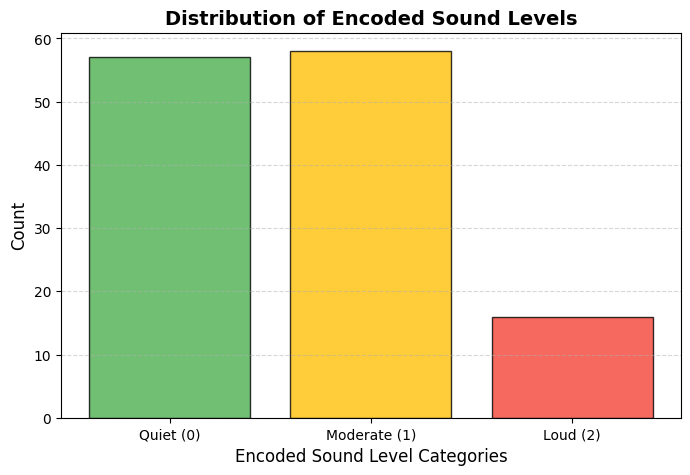

In [8]:
# Group and count the non-null encoded sound levels
sound_counts = df['sound_level_encoded'].dropna().value_counts().sort_index()

# Map indices back to their labels for the plot x-axis
labels = ['Quiet (0)', 'Moderate (1)', 'Loud (2)']

# Create the bar plot
plt.figure(figsize=(8, 5))
plt.bar(labels, sound_counts.values, color=['#4CAF50', '#FFC107', '#F44336'], edgecolor='black', alpha=0.8)

# Customizing labels and titles
plt.title('Distribution of Encoded Sound Levels', fontsize=14, fontweight='bold')
plt.xlabel('Encoded Sound Level Categories', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Display the plot
plt.show()

### Weather hot encoding using pandas

In [7]:
# Search for 'weather' in the columns
if 'weather' in df.columns:
  print(df['weather'].value_counts(dropna=False))
else:
  print("weather not found")

weather
NaN              863
Sunny             79
Partly cloudy     36
Cloudy             7
sunny              5
Windy              4
Name: count, dtype: int64
